# Financial-Inclusion-Machine-Learning-Model

In [2]:
#loading python packages.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Loading and inspection

In [3]:
#loading the training and testing dataset
train_set = pd.read_csv("data/train.csv")
test_set=  pd.read_csv("data/test.csv")
print("training data dimension: ",train_set.shape)
print("testing data dimension: ",test_set.shape)
print("number of data points (training set)->", train_set.shape[0])
print("number of data points (testing set)->", test_set.shape[0])

training data dimension:  (23524, 13)
testing data dimension:  (10086, 12)
number of data points (training set)-> 23524
number of data points (testing set)-> 10086


## Inspecting dataset

In [4]:
train_set.head() # glimpse of training set.

,country,year,uniqueid,bank_account,location_type,cellphone_access,household_size,age_of_respondent,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
0,Kenya,2018,uniqueid_1,Yes,Rural,Yes,3,24,Female,Spouse,Married/Living together,Secondary education,Self employed
1,Kenya,2018,uniqueid_2,No,Rural,No,5,70,Female,Head of Household,Widowed,No formal education,Government Dependent
2,Kenya,2018,uniqueid_3,Yes,Urban,Yes,5,26,Male,Other relative,Single/Never Married,Vocational/Specialised training,Self employed
3,Kenya,2018,uniqueid_4,No,Rural,Yes,5,34,Female,Head of Household,Married/Living together,Primary education,Formally employed Private
4,Kenya,2018,uniqueid_5,No,Urban,No,8,26,Male,Child,Single/Never Married,Primary education,Informally employed


In [5]:
test_set.head() # glimpse of test set

,country,year,uniqueid,location_type,cellphone_access,household_size,age_of_respondent,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
0,Kenya,2018,uniqueid_6056,Urban,Yes,3,30,Male,Head of Household,Married/Living together,Secondary education,Formally employed Government
1,Kenya,2018,uniqueid_6060,Urban,Yes,7,51,Male,Head of Household,Married/Living together,Vocational/Specialised training,Formally employed Private
2,Kenya,2018,uniqueid_6065,Rural,No,3,77,Female,Parent,Married/Living together,No formal education,Remittance Dependent
3,Kenya,2018,uniqueid_6072,Rural,No,6,39,Female,Head of Household,Married/Living together,Primary education,Remittance Dependent
4,Kenya,2018,uniqueid_6073,Urban,No,3,16,Male,Child,Single/Never Married,Secondary education,Remittance Dependent


In [6]:
train_set.info() # column fields information of training data


<class 'pandas.DataFrame'>
RangeIndex: 23524 entries, 0 to 23523
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   country                 23524 non-null  str  
 1   year                    23524 non-null  int64
 2   uniqueid                23524 non-null  str  
 3   bank_account            23524 non-null  str  
 4   location_type           23524 non-null  str  
 5   cellphone_access        23524 non-null  str  
 6   household_size          23524 non-null  int64
 7   age_of_respondent       23524 non-null  int64
 8   gender_of_respondent    23524 non-null  str  
 9   relationship_with_head  23524 non-null  str  
 10  marital_status          23524 non-null  str  
 11  education_level         23524 non-null  str  
 12  job_type                23524 non-null  str  
dtypes: int64(3), str(10)
memory usage: 4.6 MB


In [7]:
test_set.info() # column fields information of training data

<class 'pandas.DataFrame'>
RangeIndex: 10086 entries, 0 to 10085
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   country                 10086 non-null  str  
 1   year                    10086 non-null  int64
 2   uniqueid                10086 non-null  str  
 3   location_type           10086 non-null  str  
 4   cellphone_access        10086 non-null  str  
 5   household_size          10086 non-null  int64
 6   age_of_respondent       10086 non-null  int64
 7   gender_of_respondent    10086 non-null  str  
 8   relationship_with_head  10086 non-null  str  
 9   marital_status          10086 non-null  str  
 10  education_level         10086 non-null  str  
 11  job_type                10086 non-null  str  
dtypes: int64(3), str(9)
memory usage: 1.9 MB


In [11]:
train_set.describe().round(2) # descriptive statistics of numeric field of the training set.

,year,household_size,age_of_respondent
count,23524.00,23524.00,23524.00
mean,2016.98,3.80,38.81
std,0.85,2.23,16.52
min,2016.00,1.00,16.00
25%,2016.00,2.00,26.00
50%,2017.00,3.00,35.00
75%,2018.00,5.00,49.00
max,2018.00,21.00,100.00


In [12]:
test_set.describe().round(2) # descriptive statistics of numeric field of the testing set.

,year,household_size,age_of_respondent
count,10086.00,10086.00,10086.00
mean,2016.98,3.78,38.31
std,0.85,2.21,16.27
min,2016.00,1.00,16.00
25%,2016.00,2.00,26.00
50%,2017.00,3.00,35.00
75%,2018.00,5.00,48.00
max,2018.00,20.00,100.00


In [12]:
train_set.select_dtypes("str").describe()  # descriptive statistics of categorical field of the training set.

,country,uniqueid,bank_account,location_type,cellphone_access,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
count,23524,23524,23524,23524,23524,23524,23524,23524,23524,23524
unique,4,8735,2,2,2,2,6,5,6,10
top,Rwanda,uniqueid_1,No,Rural,Yes,Female,Head of Household,Married/Living together,Primary education,Self employed
freq,8735,4,20212,14343,17454,13877,12831,10749,12791,6437


In [13]:
test_set.select_dtypes("str").describe()  # descriptive statistics of categorical field of the testing set.

,country,uniqueid,location_type,cellphone_access,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
count,10086,10086,10086,10086,10086,10086,10086,10086,10086
unique,4,7313,2,2,2,6,5,6,10
top,Rwanda,uniqueid_8535,Rural,Yes,Female,Head of Household,Married/Living together,Primary education,Self employed
freq,3745,3,6189,7559,5847,5487,4663,5479,2773


## Exploratory data analysis

### Exploratory data analysis on training dataset

In [14]:

# exploratory data analysis on categorical data.
categ = train_set.select_dtypes("str")
print(categ.columns)

Index(['country', 'uniqueid', 'bank_account', 'location_type',
       'cellphone_access', 'gender_of_respondent', 'relationship_with_head',
       'marital_status', 'education_level', 'job_type'],
      dtype='str')


In [15]:
categ.head() # glimpse of categorical data

,country,uniqueid,bank_account,location_type,cellphone_access,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
0,Kenya,uniqueid_1,Yes,Rural,Yes,Female,Spouse,Married/Living together,Secondary education,Self employed
1,Kenya,uniqueid_2,No,Rural,No,Female,Head of Household,Widowed,No formal education,Government Dependent
2,Kenya,uniqueid_3,Yes,Urban,Yes,Male,Other relative,Single/Never Married,Vocational/Specialised training,Self employed
3,Kenya,uniqueid_4,No,Rural,Yes,Female,Head of Household,Married/Living together,Primary education,Formally employed Private
4,Kenya,uniqueid_5,No,Urban,No,Male,Child,Single/Never Married,Primary education,Informally employed


In [ ]:
### Distribution of categorical data

In [16]:
# count of each category in the categorical columns
cols = ['country', 'bank_account', 'location_type',
       'cellphone_access', 'gender_of_respondent', 'relationship_with_head',
       'marital_status', 'education_level', 'job_type']
for col in cols:

    print(train_set[col].value_counts(), '\n', '-----------------------------', '\n')

country
Rwanda      8735
Tanzania    6620
Kenya       6068
Uganda      2101
Name: count, dtype: int64 
 ----------------------------- 

bank_account
No     20212
Yes     3312
Name: count, dtype: int64 
 ----------------------------- 

location_type
Rural    14343
Urban     9181
Name: count, dtype: int64 
 ----------------------------- 

cellphone_access
Yes    17454
No      6070
Name: count, dtype: int64 
 ----------------------------- 

gender_of_respondent
Female    13877
Male       9647
Name: count, dtype: int64 
 ----------------------------- 

relationship_with_head
Head of Household      12831
Spouse                  6520
Child                   2229
Parent                  1086
Other relative           668
Other non-relatives      190
Name: count, dtype: int64 
 ----------------------------- 

marital_status
Married/Living together    10749
Single/Never Married        7983
Widowed                     2708
Divorced/Seperated          2076
Dont know                      8
Name: co

In [21]:
# percentage of each item  in the categorical columns
cols = ['country', 'bank_account', 'location_type',
       'cellphone_access', 'gender_of_respondent', 'relationship_with_head',
       'marital_status', 'education_level', 'job_type']
for col in cols:

    print((train_set[col].\
        value_counts()/train_set[col].\
        value_counts().sum()).round(2)*100, '\n', '-----------------------------', '\n')

country
Rwanda      37.0
Tanzania    28.0
Kenya       26.0
Uganda       9.0
Name: count, dtype: float64 
 ----------------------------- 

bank_account
No     86.0
Yes    14.0
Name: count, dtype: float64 
 ----------------------------- 

location_type
Rural    61.0
Urban    39.0
Name: count, dtype: float64 
 ----------------------------- 

cellphone_access
Yes    74.0
No     26.0
Name: count, dtype: float64 
 ----------------------------- 

gender_of_respondent
Female    59.0
Male      41.0
Name: count, dtype: float64 
 ----------------------------- 

relationship_with_head
Head of Household      55.0
Spouse                 28.0
Child                   9.0
Parent                  5.0
Other relative          3.0
Other non-relatives     1.0
Name: count, dtype: float64 
 ----------------------------- 

marital_status
Married/Living together    46.0
Single/Never Married       34.0
Widowed                    12.0
Divorced/Seperated          9.0
Dont know                   0.0
Name: count, dt

### Data visualization on categorical data ( training dataset_)

In [22]:
# reshape training data for visualization purpose
train_melt = pd.melt(train_set, 
                     value_vars=cols, 
                     var_name= "feature", 
                     value_name="category")
train_melt.head()

,feature,category
0,country,Kenya
1,country,Kenya
2,country,Kenya
3,country,Kenya
4,country,Kenya


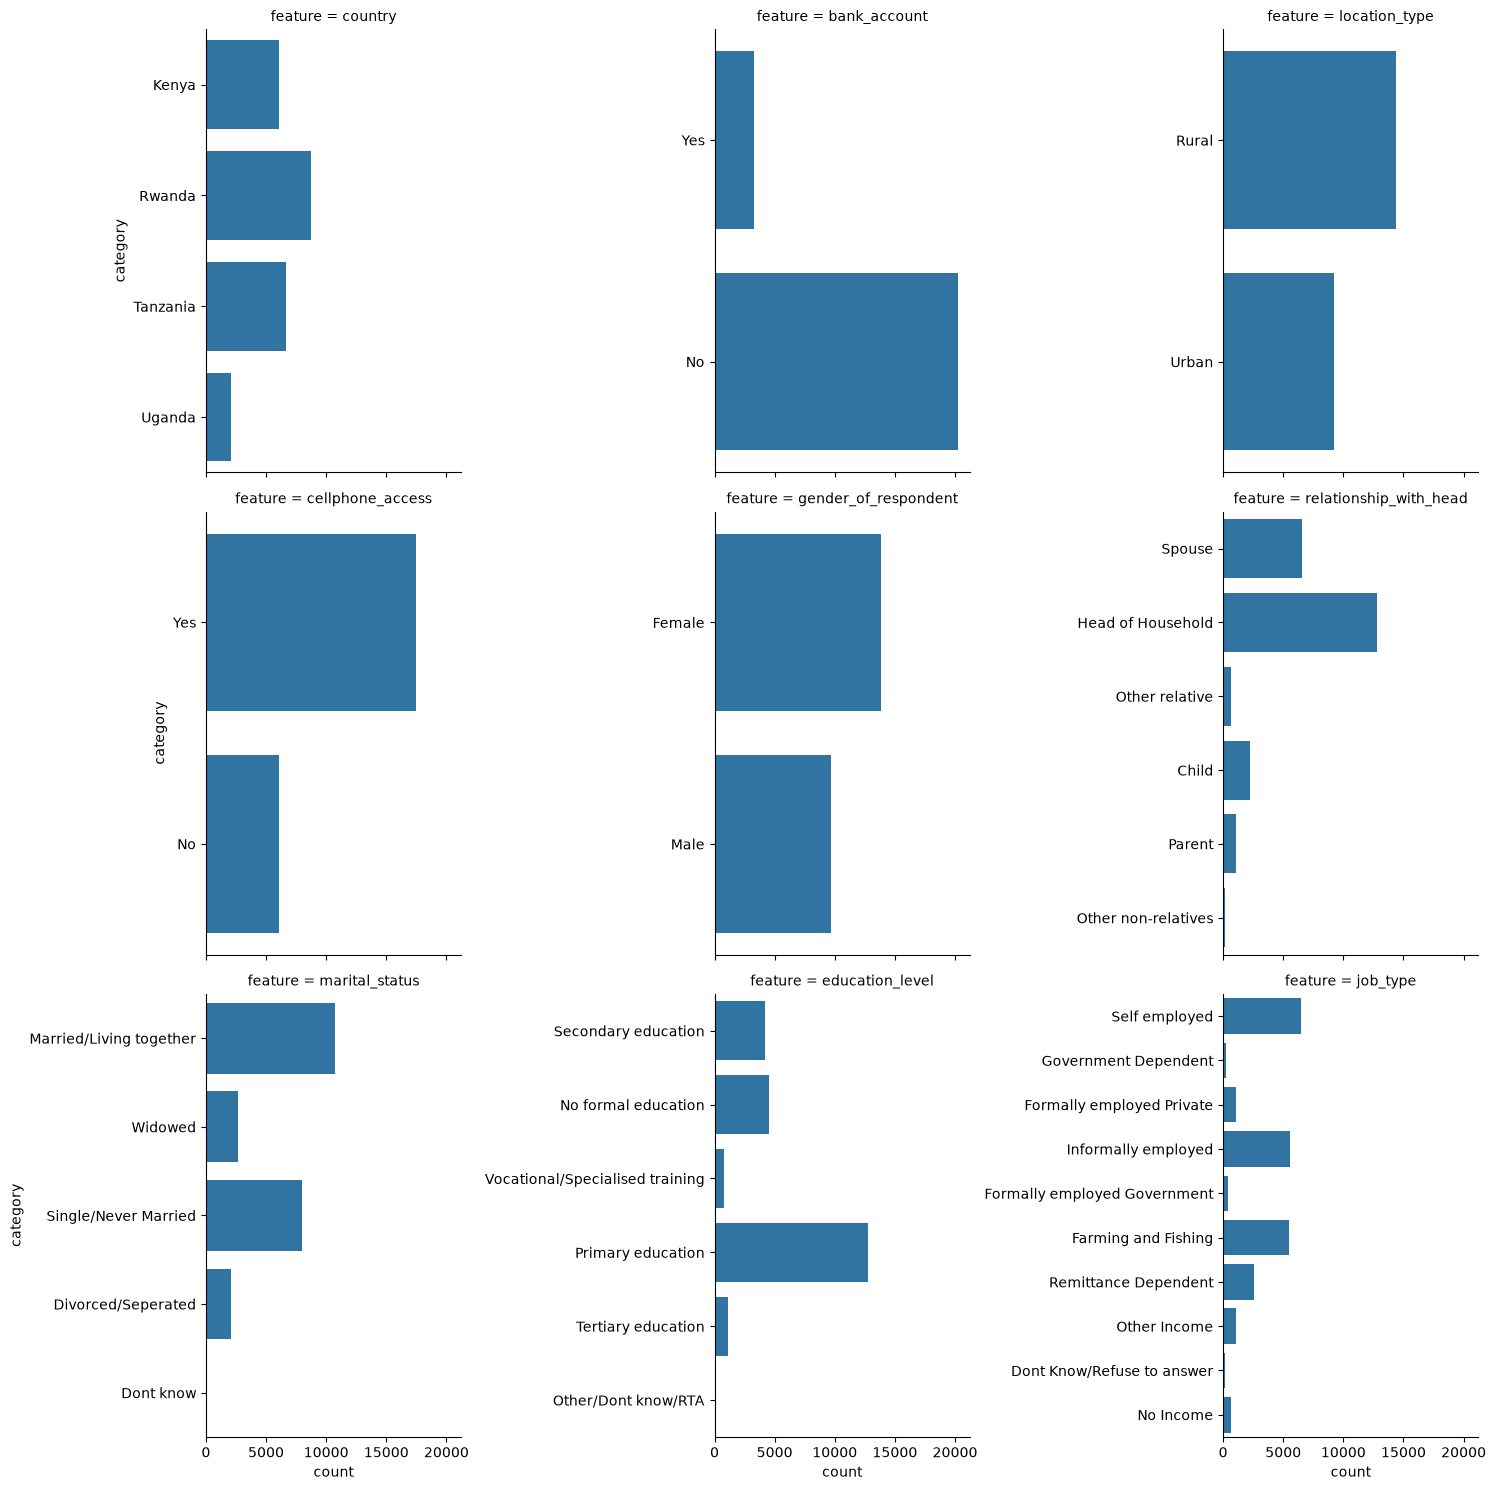

In [23]:
# count plot of categorical columns
g= sns.catplot(
               data=train_melt, 
               y='category',# horizontal barchart 
               col='feature', 
               kind='count', 
               sharey=False, 
               col_wrap=3, )
plt.show()

## Exploratory data analysis on numerical data (training dataset)

In [24]:
num = train_set.select_dtypes(['int', 'float']) # selects only columns with numerical data
num_cols = list(num)[1:] # numerical column list
print("numerical column list: ", num_cols)

numerical column list:  ['household_size', 'age_of_respondent']


In [25]:
# numerical data - training set
train_set_num = train_set[num_cols]
train_set_num.head()

,household_size,age_of_respondent
0,3,24
1,5,70
2,5,26
3,5,34
4,8,26


In [27]:
train_set_num.describe().T # descriptive statistics of numerical columns

,count,mean,std,min,25%,50%,75%,max
household_size,23524.0,3.797483,2.227613,1.0,2.0,3.0,5.0,21.0
age_of_respondent,23524.0,38.805220,16.520569,16.0,26.0,35.0,49.0,100.0


### Data visualization on numerical data (training dataset)

In [46]:
# reshaping the numerical data for data visualization purpose
train_num_melt = pd.melt(
                        train_set[num_cols], 
                         var_name="feature", 
                         value_name="value", 
                         value_vars=num_cols)

In [52]:
train_num_melt.head()

,feature,value
0,household_size,3
1,household_size,5
2,household_size,5
3,household_size,5
4,household_size,8


<Axes: >

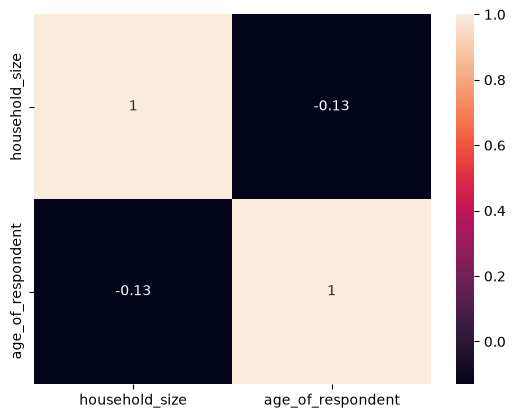

In [26]:
# correlation between household size and age of respondent

sns.heatmap(data = train_set_num.corr(), annot=True)

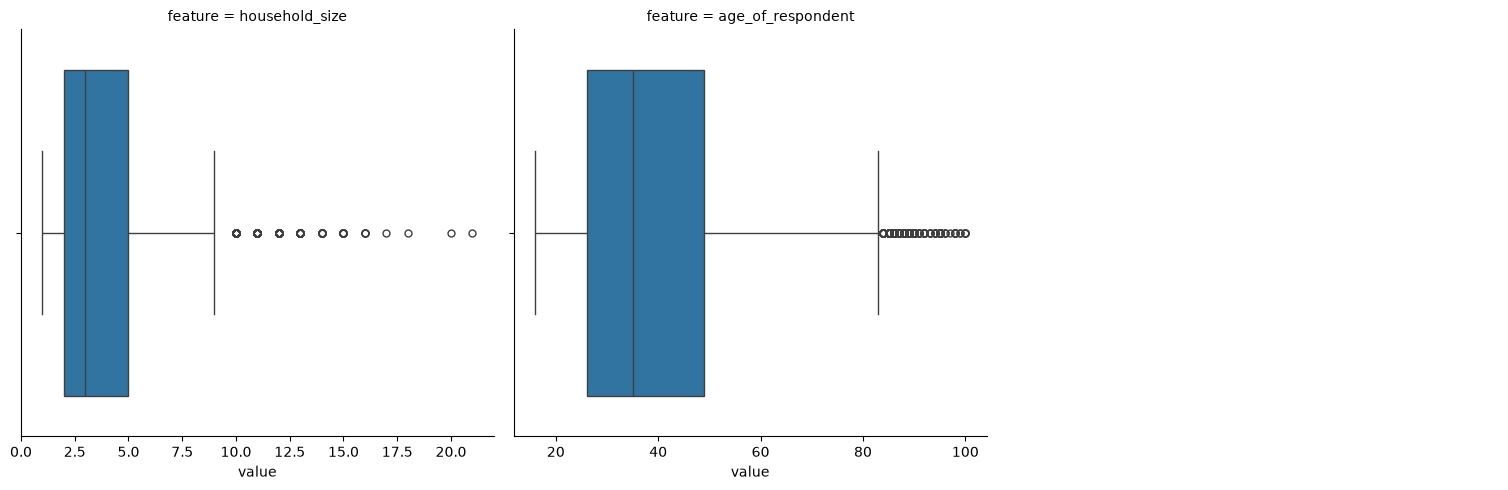

In [62]:
#  distribution plot of numerical columns
g= sns.catplot(
               data=train_num_melt, 
               x='value',# horizontal barchart 
               col='feature', 
               kind='box', 
               sharex=False, 
               col_wrap=3, )
plt.show()

## Repeating data inspection and exploratory data analysis step for the test dataset
----

## Data inspection 

In [32]:
test_set.head() # glimpse of test set

,country,year,uniqueid,location_type,cellphone_access,household_size,age_of_respondent,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
0,Kenya,2018,uniqueid_6056,Urban,Yes,3,30,Male,Head of Household,Married/Living together,Secondary education,Formally employed Government
1,Kenya,2018,uniqueid_6060,Urban,Yes,7,51,Male,Head of Household,Married/Living together,Vocational/Specialised training,Formally employed Private
2,Kenya,2018,uniqueid_6065,Rural,No,3,77,Female,Parent,Married/Living together,No formal education,Remittance Dependent
3,Kenya,2018,uniqueid_6072,Rural,No,6,39,Female,Head of Household,Married/Living together,Primary education,Remittance Dependent
4,Kenya,2018,uniqueid_6073,Urban,No,3,16,Male,Child,Single/Never Married,Secondary education,Remittance Dependent


In [33]:
test_set.info() # column fields information of training data

<class 'pandas.DataFrame'>
RangeIndex: 10086 entries, 0 to 10085
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   country                 10086 non-null  str  
 1   year                    10086 non-null  int64
 2   uniqueid                10086 non-null  str  
 3   location_type           10086 non-null  str  
 4   cellphone_access        10086 non-null  str  
 5   household_size          10086 non-null  int64
 6   age_of_respondent       10086 non-null  int64
 7   gender_of_respondent    10086 non-null  str  
 8   relationship_with_head  10086 non-null  str  
 9   marital_status          10086 non-null  str  
 10  education_level         10086 non-null  str  
 11  job_type                10086 non-null  str  
dtypes: int64(3), str(9)
memory usage: 1.9 MB


In [34]:
test_set.describe().round(2) # descriptive statistics of numeric field of the testing set.

,year,household_size,age_of_respondent
count,10086.00,10086.00,10086.00
mean,2016.98,3.78,38.31
std,0.85,2.21,16.27
min,2016.00,1.00,16.00
25%,2016.00,2.00,26.00
50%,2017.00,3.00,35.00
75%,2018.00,5.00,48.00
max,2018.00,20.00,100.00


In [31]:
test_set.select_dtypes("str").describe()  # descriptive statistics of categorical field of the testing set.

,country,uniqueid,location_type,cellphone_access,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
count,10086,10086,10086,10086,10086,10086,10086,10086,10086
unique,4,7313,2,2,2,6,5,6,10
top,Rwanda,uniqueid_8535,Rural,Yes,Female,Head of Household,Married/Living together,Primary education,Self employed
freq,3745,3,6189,7559,5847,5487,4663,5479,2773


In [36]:
# exploratory data analysis on categorical data.
categ_test = test_set.select_dtypes("str")
print(categ_test.columns)


Index(['country', 'uniqueid', 'location_type', 'cellphone_access',
       'gender_of_respondent', 'relationship_with_head', 'marital_status',
       'education_level', 'job_type'],
      dtype='str')


In [38]:
### Distribution of categorical data


# count of each category in the categorical columns
cols_test = ['country', 'location_type',
       'cellphone_access', 'gender_of_respondent', 'relationship_with_head',
       'marital_status', 'education_level', 'job_type']
for col in cols_test:

    print(test_set[col].value_counts(), '\n', '-----------------------------', '\n')


country
Rwanda      3745
Tanzania    2839
Kenya       2601
Uganda       901
Name: count, dtype: int64 
 ----------------------------- 

location_type
Rural    6189
Urban    3897
Name: count, dtype: int64 
 ----------------------------- 

cellphone_access
Yes    7559
No     2527
Name: count, dtype: int64 
 ----------------------------- 

gender_of_respondent
Female    5847
Male      4239
Name: count, dtype: int64 
 ----------------------------- 

relationship_with_head
Head of Household      5487
Spouse                 2845
Child                   962
Parent                  465
Other relative          258
Other non-relatives      69
Name: count, dtype: int64 
 ----------------------------- 

marital_status
Married/Living together    4663
Single/Never Married       3447
Widowed                    1107
Divorced/Seperated          868
Dont know                     1
Name: count, dtype: int64 
 ----------------------------- 

education_level
Primary education                  5479
Secondar

In [39]:
# percentage of each category in the categorical columns
cols_test = ['country', 'location_type',
       'cellphone_access', 'gender_of_respondent', 'relationship_with_head',
       'marital_status', 'education_level', 'job_type']
for col in cols_test:

    print((test_set[col].\
        value_counts()/test_set[col].\
        value_counts().sum()).round(2)*100, '\n', '-----------------------------', '\n')

country
Rwanda      37.0
Tanzania    28.0
Kenya       26.0
Uganda       9.0
Name: count, dtype: float64 
 ----------------------------- 

location_type
Rural    61.0
Urban    39.0
Name: count, dtype: float64 
 ----------------------------- 

cellphone_access
Yes    75.0
No     25.0
Name: count, dtype: float64 
 ----------------------------- 

gender_of_respondent
Female    58.0
Male      42.0
Name: count, dtype: float64 
 ----------------------------- 

relationship_with_head
Head of Household      54.0
Spouse                 28.0
Child                  10.0
Parent                  5.0
Other relative          3.0
Other non-relatives     1.0
Name: count, dtype: float64 
 ----------------------------- 

marital_status
Married/Living together    46.0
Single/Never Married       34.0
Widowed                    11.0
Divorced/Seperated          9.0
Dont know                   0.0
Name: count, dtype: float64 
 ----------------------------- 

education_level
Primary education                  5

In [41]:
# reshape training data for visualization purpose
test_set2 = test_set[cols_test]
test_melt = pd.melt(test_set2, 
                     value_vars=cols_test, 
                     var_name= "feature", 
                     value_name="category")
test_melt.head()

,feature,category
0,country,Kenya
1,country,Kenya
2,country,Kenya
3,country,Kenya
4,country,Kenya


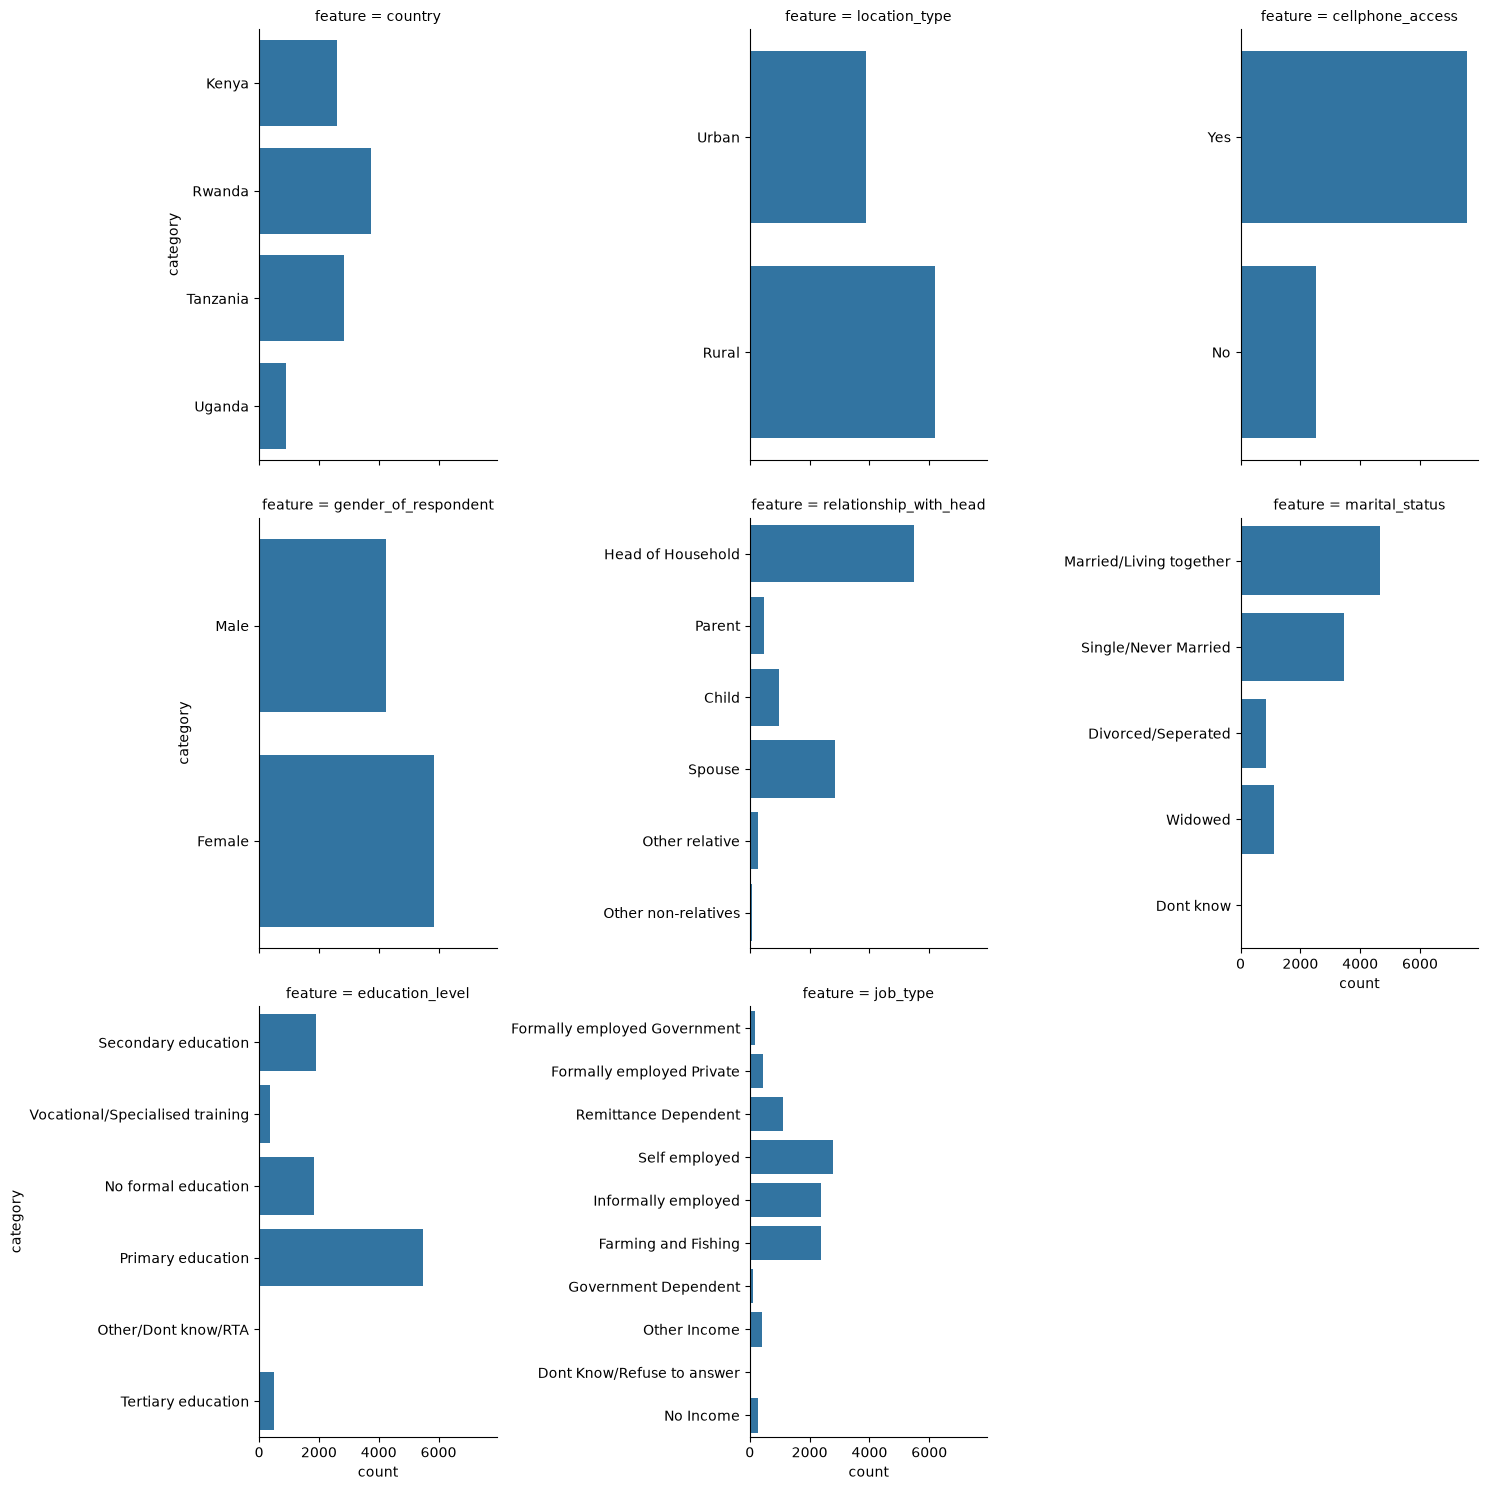

In [42]:
g= sns.catplot(
               data=test_melt, 
               y='category',# horizontal barchart 
               col='feature', 
               kind='count', 
               sharey=False, 
               col_wrap=3, )
plt.show()


## Preparing data for model training

In [47]:
list(train_set) # columns of the training dataset

['country',
 'year',
 'uniqueid',
 'bank_account',
 'location_type',
 'cellphone_access',
 'household_size',
 'age_of_respondent',
 'gender_of_respondent',
 'relationship_with_head',
 'marital_status',
 'education_level',
 'job_type']

In [48]:
# re-arranging the column fields for model building purpose
train_cols = [
    'country',
 'year',
 'location_type',
 'cellphone_access',
 'household_size',
 'age_of_respondent',
 'gender_of_respondent',
 'relationship_with_head',
 'marital_status',
 'education_level',
 'job_type',
 'bank_account'] # re-arranging the dependent and independent variables.

training_set1 = train_set[train_cols]
training_set1.head()

,country,year,location_type,cellphone_access,household_size,age_of_respondent,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type,bank_account
0,Kenya,2018,Rural,Yes,3,24,Female,Spouse,Married/Living together,Secondary education,Self employed,Yes
1,Kenya,2018,Rural,No,5,70,Female,Head of Household,Widowed,No formal education,Government Dependent,No
2,Kenya,2018,Urban,Yes,5,26,Male,Other relative,Single/Never Married,Vocational/Specialised training,Self employed,Yes
3,Kenya,2018,Rural,Yes,5,34,Female,Head of Household,Married/Living together,Primary education,Formally employed Private,No
4,Kenya,2018,Urban,No,8,26,Male,Child,Single/Never Married,Primary education,Informally employed,No


In [49]:
list(test_set)

['country',
 'year',
 'uniqueid',
 'location_type',
 'cellphone_access',
 'household_size',
 'age_of_respondent',
 'gender_of_respondent',
 'relationship_with_head',
 'marital_status',
 'education_level',
 'job_type']

In [50]:
test_cols = ['country',
 'year',
 'location_type',
 'cellphone_access',
 'household_size',
 'age_of_respondent',
 'gender_of_respondent',
 'relationship_with_head',
 'marital_status',
 'education_level',
 'job_type']

testing_set1 = test_set[test_cols]
testing_set1.head()

,country,year,location_type,cellphone_access,household_size,age_of_respondent,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
0,Kenya,2018,Urban,Yes,3,30,Male,Head of Household,Married/Living together,Secondary education,Formally employed Government
1,Kenya,2018,Urban,Yes,7,51,Male,Head of Household,Married/Living together,Vocational/Specialised training,Formally employed Private
2,Kenya,2018,Rural,No,3,77,Female,Parent,Married/Living together,No formal education,Remittance Dependent
3,Kenya,2018,Rural,No,6,39,Female,Head of Household,Married/Living together,Primary education,Remittance Dependent
4,Kenya,2018,Urban,No,3,16,Male,Child,Single/Never Married,Secondary education,Remittance Dependent


In [62]:
#import preprocessing module
from sklearn.preprocessing import LabelEncoder
#from sklearn.preprocessing import MinMaxScaler

# Convert target label to numerical Data
le = LabelEncoder()
training_set1['bank_account'] = le.fit_transform(training_set1['bank_account'])

#Separate training features from target
X_train = training_set1.drop(['bank_account'], axis=1)
y_train = training_set1['bank_account']

print(y_train)

0        1
1        0
2        1
3        0
4        0
        ..
23519    0
23520    0
23521    0
23522    0
23523    0
Name: bank_account, Length: 23524, dtype: int64


In [64]:
# METHOD 1: preprocess training dataset using custom function.
# A function to preprocess our data from train models.

#import libraries
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler

def preprocess_data(data):
        
    le = LabelEncoder()
    
    # Convert numerical labels from interger to float
    float_array = data[["household_size", "age_of_respondent", "year"]].values.astype(float)

    # convert categorical features to One Hot Encoding
    categ = ["relationship_with_head",
             "marital_status",
             "education_level",
             "job_type",
             "country"]

    # One Hot Encoding conversion
    data = pd.get_dummies(data, prefix_sep="_", columns=categ)

    # Label Encoder conversion
    data["location_type"] = le.fit_transform(data["location_type"])
    data["cellphone_access"] = le.fit_transform(data["cellphone_access"])
    data["gender_of_respondent"] = le.fit_transform(data["gender_of_respondent"])

   
    # scale our data into range of 0 and 1
    scaler = MinMaxScaler(feature_range=(0, 1))
    data = scaler.fit_transform(data)

    return data
    

In [65]:
prep_train = preprocess_data(X_train)
prep_test = preprocess_data(testing_set1)

In [66]:
prep_train

array([[1., 0., 1., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       [1., 1., 1., ..., 0., 0., 0.],
       ...,
       [1., 0., 1., ..., 0., 0., 1.],
       [1., 1., 1., ..., 0., 0., 1.],
       [1., 0., 1., ..., 0., 0., 1.]], shape=(23524, 37))

In [67]:
prep_test

array([[1., 1., 1., ..., 0., 0., 0.],
       [1., 1., 1., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       ...,
       [1., 1., 1., ..., 0., 0., 1.],
       [1., 0., 1., ..., 0., 0., 1.],
       [1., 1., 1., ..., 0., 0., 1.]], shape=(10086, 37))